In [1]:
import sys
import yaml
import numpy as np
import pandas as pd
from pathlib import Path

sys.path.append("../..")
from src.solvers.ortools import solve_wflo_cpsat
from src.solvers.utils import save_benchmark_layout
from src.qubo_windfarm_layout.evaluation import load_layout_coordinates, layouts_folder_to_df
from src.qubo_windfarm_layout.visualization import plot_gurobi_refinement, plot_selected_layout
from src.qubo_windfarm_layout.model import build_local_candidates, get_warmstart, get_farm_area, build_local_wake_loss_matrix_optimized


# Strategies
Faccio una prima run grezza con risoluzione tale che ho invalid pairs non nulle e wake loss migliori della baseline.
Ho scelto GRID_RESOLUTION = 128m e TIMEOUT = 30m

Faccio run con GRID_RESOLUTION che va come potenza di due (64 -> 32 -> 16 -> 8) e raggio uguale a 2*GRID_RESOLUTION, TIMEOUT di 30m


In [2]:
# Variables
GRID_RESOLUTION = 8
TIMEOUT = 60 * 30
SOLVER = "ortools_cpsat"
STARTING_LAYOUT = f"../../results/layouts/{SOLVER}/ortools_cpsat_local_16m_1800s_warmstart.yaml"

# Parameters
RADIUS = 2*GRID_RESOLUTION
WAKE_LOSS_PATH = f"../../results/precomputed/{SOLVER}/wake_loss_{SOLVER}_res_{GRID_RESOLUTION}m_rad_{RADIUS}.npz"

(746, 2)
(3298, 2)


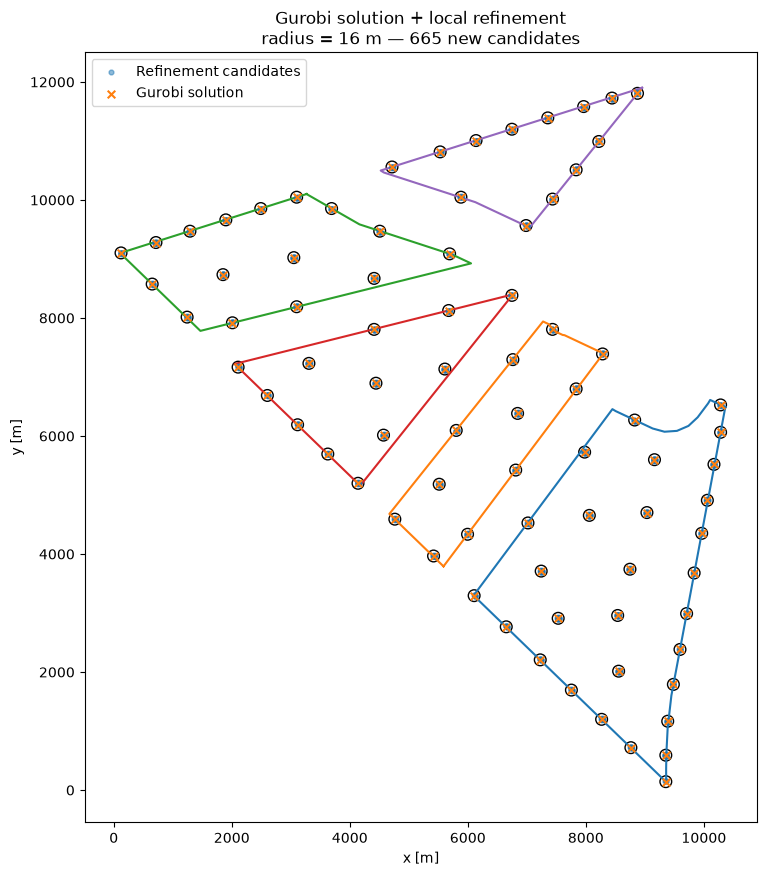

In [3]:
gurobi_positions = load_layout_coordinates(STARTING_LAYOUT)

_, farm_area = get_farm_area()

candidate_locations, invalid_pairs = build_local_candidates(
    gurobi_positions=gurobi_positions,
    farm_area=farm_area,
    radius_m=RADIUS,
    step_m=GRID_RESOLUTION,
)

print(candidate_locations.shape)
print(invalid_pairs.shape)

plot_gurobi_refinement(
    gurobi_positions=gurobi_positions,
    candidate_locations=candidate_locations,
    radius_m=RADIUS,
)

In [4]:
wake_loss_matrix, A0 = build_local_wake_loss_matrix_optimized(
    candidate_locations,
    output_path=WAKE_LOSS_PATH
)

wake_loss_matrix = np.load(WAKE_LOSS_PATH)["wake_loss_matrix"]

warm_start = get_warmstart(candidate_locations=candidate_locations, starting_layout=STARTING_LAYOUT)

Numero candidate locations: 746
Numero coppie totali: 277,885
Numero displacement unici: 88,723
Wake-loss data saved to: ../../results/precomputed/ortools_cpsat/wake_loss_ortools_cpsat_res_8m_rad_16.npz


In [5]:
result = solve_wflo_cpsat(
    wake_loss_matrix=wake_loss_matrix,
    invalid_pairs=invalid_pairs,
    n_turbines=81,
    warmstart=warm_start,
    time_limit_s=TIMEOUT,
)

Status: FEASIBLE
Turbine selezionate: 81
Pairwise wake loss: 838410.038


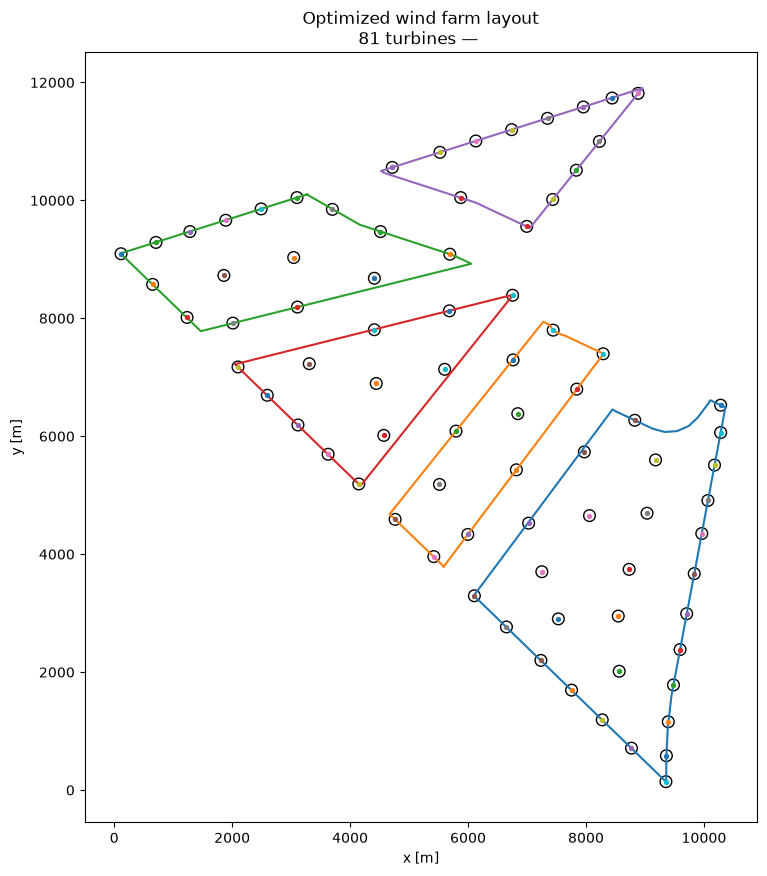

Layout saved to: /home/maicolnicolini/code/qubo-wind-farm-layout/notebooks/pipelines/../../results/layouts/ortools_cpsat/ortools_cpsat_local_8m_1800s_warmstart.yaml
H_QUBO: 838410.0475590809
AEP: 2902.580287 GWh


PosixPath('/home/maicolnicolini/code/qubo-wind-farm-layout/notebooks/pipelines/../../results/layouts/ortools_cpsat/ortools_cpsat_local_8m_1800s_warmstart.yaml')

In [6]:
selected_indices = np.flatnonzero(result[0])
selected_locations = candidate_locations[
    selected_indices
]

plot_selected_layout(selected_locations=selected_locations)

save_benchmark_layout(
    selected_locations=selected_locations,
    solver_name="ortools",
    output_dir=f"results/layouts/ortools_cpsat",
    filename=f"ortools_cpsat_local_{GRID_RESOLUTION}m_{TIMEOUT}s_warmstart.yaml",
    grid_resolution=GRID_RESOLUTION,
    time_limit_s=TIMEOUT,
    candidate_locations=candidate_locations,
    wake_loss_matrix=wake_loss_matrix,
)

In [7]:
df = layouts_folder_to_df(
    f"../../results/layouts/{SOLVER}"
)

df.sort_values(by="h_qubo", ascending=True)

,file,solver,grid_resolution,n_turbines,time_limit_s,h_qubo,aep_gwh
6,ortools_cpsat_local_8m_1800s_warmstart.yaml,ortools,8,81,1800,838410.047559,2902.580287
2,ortools_cpsat_local_16m_1800s_warmstart.yaml,ortools,16,81,1800,839796.373324,2901.748183
4,ortools_cpsat_local_32m_1800s_warmstart.yaml,ortools,32,81,1800,842937.172863,2899.716914
5,ortools_cpsat_local_64m_1800s_warmstart.yaml,ortools,64,81,1800,850215.608720,2894.411872
1,ortools_cpsat_local_128m_1800s_warmstart.yaml,ortools,128,81,1800,868173.077127,2882.512713
3,ortools_cpsat_local_256m_1800s_warmstart.yaml,ortools,256,81,1800,903237.319049,2855.004908
0,cpsat_256_3600s.yaml,cpsat,256,81,3600,NaN,2853.761924
